**BB84 Quantum Key Distribution**

**References**
1. Lo, Hoi-Kwong, Chau, H. F., and Ardehali, M. (November 26, 2024). *Effecient Quantum Key Distribution Scheme and Proof of its Unconditional Security*. 
2. Gao, T., Rickert, L., Urban, F. et. al.

In [ ]:
# imports for quantum circuit construction
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp # observables
from qiskit.primitives import StatevectorSampler # sampler
from qiskit.transpiler import generate_preset_pass_manager # transpiler


# plotting imports
from matplotlib import pyplot as plt

# Runtime imports
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.options_models import EstimatorOptions
from qiskit_ibm_runtime.executor_estimator import Estimator
from qiskit_ibm_runtime.executor_sampler import Sampler

In [ ]:
# Global configuration variables

SIM_BACKEND = False # Set to True to use a simulator, False to use a real backend. If True, the code will use the FakeBelemV2 backend. If False, it will use the least busy operational backend.
QUBITS = 1 # Number of qubits to use in the circuit.
RESILIENCE_LEVEL = 1 # Resilience level for the Estimator. 0 = no resilience, 1 = readout error mitigation, 2 = gate error mitigation, 3 = both readout and gate error mitigation.
SHOTS = 1024 # Number of shots to use for the Sampler OR Estimator. This is the number of times the circuit will be run to collect measurement statistics.

In [ ]:
# Initialize the Qiskit Runtime Service and select the backend based on the SIM_BACKEND flag.

service = QiskitRuntimeService()
if SIM_BACKEND:
    from qiskit_ibm_runtime.fake_provider import FakeBelemV2
    backend = FakeBelemV2()
else:
    backend = QiskitRuntimeService().least_busy(simulator=False, operational=True) # can fail when no matching simulator exists.

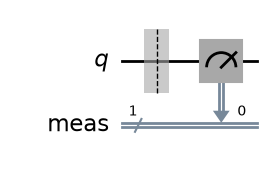

In [ ]:
# Build Alice's qubits and show circuit (local simulation)

# Initialize Alice at |0>
alice = QuantumCircuit(QUBITS)
#alice.x(0)  # Apply Hadamard gate to create superposition
alice.measure_all()
alice.draw("mpl")

In [ ]:
# Ideal sampler (no error) for Alice's circuit (local simulation)

sampler = StatevectorSampler()
result = sampler.run([alice], shots=1024).result()
print(result[0].data.meas.get_counts())

{'0': 1024}


In [ ]:
# Set up bases for different observables.

observables_labels = ["Z", "X", "Y"]
observables = [SparsePauliOp(label) for label in observables_labels]

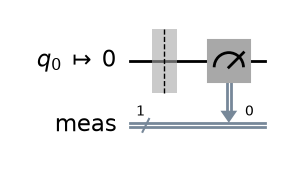

In [ ]:
# Build Alice's circuit for the Estimator and Sampler primitives.

# Convert to an ISA circuit and layout-mapped observables.
pm = generate_preset_pass_manager(backend=backend, optimization_level=1) # sets up the pass manager for the backend
isa_circuit_alice = pm.run(alice) # run the pass manager on Alice's circuit to get the ISA circuit
isa_circuit_alice.draw("mpl", idle_wires=False) # hide idle wires for better visualization

In [ ]:
# Construct the Estimator instance.
estimator = Estimator(mode=backend)
estimator.options.resilience_level = RESILIENCE_LEVEL
estimator.options.default_shots = SHOTS

# The observables are 2-qubit Pauli strings, so the circuit must also be 2 qubits.
mapped_observables = [
    observable.apply_layout(isa_circuit_alice.layout) for observable in observables
]

# One pub, with one circuit to run against five different observables.
job_alice = estimator.run([(isa_circuit_alice, mapped_observables)])

# Use the job ID to retrieve your job data later
print(f">>> Job ID: {job_alice.job_id()}")

>>> Job ID: dbdtovgm94ac738qtj30


In [ ]:
# Error Rate Calculation
sampler = Sampler(mode=backend)
job_alice = sampler.run([isa_circuit_alice], shots=1024)
print("Job ID:", job_alice.job_id())

counts = job_alice.result()[0].data.meas.get_counts()
error_rate = counts.get("1", 0) / sum(counts.values())

print("Counts:", counts)
print(f"|0> error rate: {error_rate:.2%}")

Job ID: dbdu1j7pc3tc739kpkag
Counts: {'0': 1018, '1': 6}
|0> error rate: 0.59%


In [ ]:
job_result_alice = job_alice.result() # get the result of the job
pub_result_alice = job_result_alice[0] # get the result for the first circuit (Alice's circuit)

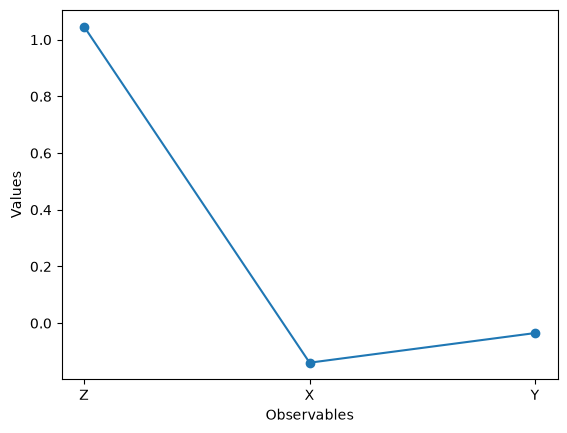

In [199]:
# Plot the result
values_alice = pub_result_alice.data.evs
errors_alice = pub_result_alice.data.stds

# plotting graph
# Each result contains 18 values in the order: [Eve(6), Bob(6), Alice(6)]
alice_values = values_alice[:len(observables_labels)]

plt.plot(observables_labels, alice_values, marker="o", label="Alice")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.show()

In [ ]:
# Print the expectation values and standard deviations for each observable reads out [Z X Y]
print(job_result_alice[0].data.evs)
print(job_result_alice[0].data.stds)

[ 1.04585683 -0.13944758 -0.03486189]
[0.         0.02465108 0.09860433]
